# 02 · Reservoir geometry → `reservoirs.geojson`

For each reservoir we need the area of the image to read. This notebook:

1. takes each reservoir's **reference point** and **hydrographic basin** from the Portal Hidrológico do Ceará (the coordinates COGERH publishes, fixed across campaigns);
2. finds its water polygon in **OpenStreetMap** (Overpass API);
3. builds the **area of interest (AOI)**: water within 1 km of the reference point.

Why water near the point and not the whole lake: a lab sample describes the water where it was taken. Castanhão covers about 300 km²; averaging the whole lake would mix in water the sample never saw. For small reservoirs the 1 km disc covers most of the lake anyway.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))
from common import RAW, PROCESSED, OUTPUTS, normalize_name
from geometry import fetch_osm_water, osm_water_frame, match_reservoirs, build_aoi, AOI_RADIUS_M

pd.set_option("display.width", 200, "display.max_rows", 80, "display.max_colwidth", 40)
JAGUARIBE = ["Alto Jaguaribe", "Médio Jaguaribe", "Baixo Jaguaribe", "Banabuiú", "Salgado"]

## Reference points and basins from the portal

Each campaign page of the portal embeds the reservoirs sampled in that campaign, with coordinates and the hydrographic region (`regiao_hidrografica`). We saved all 75 campaign pages (Feb/2008 to Aug/2026) with `src/fetch_hidro.py`.

In [2]:
rows = []
for f in sorted((RAW / "hidro" / "campanhas").glob("*.json")):
    for x in json.loads(f.read_text(encoding="utf-8")) or []:
        r = x["reservatorio"]
        rows.append({"hidro_id": r["id"], "name": r["nome"], "lat": r["latitude"], "lon": r["longitude"],
                     "basin": r["regiao_hidrografica"], "campaign": f.stem.replace("_", "-")})
camp = pd.DataFrame(rows)
camp["reservoir"] = camp["name"].map(normalize_name)

# One row per reservoir. Coordinates never change between campaigns (checked below).
spread = camp.groupby("reservoir")[["lat", "lon"]].std().max(axis=1).max()
print(f"largest coordinate spread across campaigns: {spread:.6f} degrees")
points = (camp.sort_values("campaign").groupby("reservoir")
          .agg(hidro_id=("hidro_id", "last"), name=("name", "last"), lat=("lat", "last"), lon=("lon", "last"),
               basin=("basin", "last"), first_campaign=("campaign", "first"), last_campaign=("campaign", "last"),
               n_campaigns=("campaign", "nunique")).reset_index())
print(len(points), "reservoirs")
points["basin"].value_counts()

largest coordinate spread across campaigns: 0.000000 degrees
143 reservoirs


basin
Metropolitana         23
Alto Jaguaribe        18
Banabuiú              18
Acaraú                14
Salgado               14
Médio Jaguaribe       14
Curu                  12
Coreaú                10
Sertões de Crateús    10
Litoral                8
Serra da Ibiapaba      1
Baixo Jaguaribe        1
Name: count, dtype: int64

## Which of our lab samples have a location

Samples from `01_ground_truth` whose reservoir is not on the portal cannot be matched to an image. Several are reservoirs COGERH no longer lists. Looking them up by name in OSM would be a guess (Ceará has many reservoirs called "Bonito" or "Junco"), so they are left out and listed here.

In [3]:
samples = pd.read_csv(PROCESSED / "samples.csv")
missing = samples[~samples["reservoir"].isin(points["reservoir"])]
print(f"{len(missing)} of {len(samples)} samples ({len(missing)/len(samples):.1%}) have no reference point")
missing.groupby("reservoir")["campaign"].agg(["size", "min", "max"])

246 of 3679 samples (6.7%) have no reference point


,size,min,max
reservoir,,,
bonito,18,2018-05,2024-08
broco,19,2016-02,2025-02
desterro,18,2018-08,2025-02
do coronel,28,2016-02,2025-02
escuridao,25,2016-11,2025-02
favelas,6,2021-11,2025-02
forquilha ii,5,2018-05,2025-02
gerardo atimbone,27,2016-02,2025-02
jatoba,15,2016-05,2024-08


## OpenStreetMap water polygons

One Overpass query per batch of 15 points asks for every water polygon (`natural=water` or `landuse=reservoir`) within 1.5 km, excluding rivers, canals and aquaculture tanks. Raw responses are cached in `data/raw/osm/`. Points are queried in the order of the latest campaign page, so the cache is reused.

In [4]:
latest = [x["reservatorio"]["id"] for x in json.loads((RAW / "hidro" / "campanhas" / "2026_08.json").read_text(encoding="utf-8"))]
order = {hid: i for i, hid in enumerate(latest)}
points["order"] = points["hidro_id"].map(order)
first = points[points["order"].notna()].sort_values("order")
rest = points[points["order"].isna()].sort_values("reservoir")

elements = fetch_osm_water(list(zip(first.lat, first.lon)), RAW / "osm") + \
           fetch_osm_water(list(zip(rest.lat, rest.lon)), RAW / "osm")
water = osm_water_frame(elements).drop_duplicates(["osm_type", "osm_id"])
print(len(water), "OSM water polygons near our points")

247 OSM water polygons near our points


## Match each reservoir to a polygon

Rule: take the largest polygon that contains the point; otherwise the nearest polygon within 1 km; otherwise no polygon. The OSM name is only a check. Many "different" names are spelling variants (Amanari, Truçu, Thomaz Osterne) or official names (Banabuiú is *Açude Arrojado Lisboa*, Pentecoste is *Açude Pereira de Miranda*).

In [5]:
gpts = gpd.GeoDataFrame(points, geometry=gpd.points_from_xy(points.lon, points.lat), crs="EPSG:4326")
matched = match_reservoirs(gpts, water).merge(points[["reservoir", "hidro_id", "n_campaigns"]], on="reservoir")
print(matched["match"].value_counts().to_string(), "\n")
print(matched["name_check"].replace("", "none").value_counts().to_string())
matched.loc[matched["name_check"] == "different", ["name", "basin", "match", "dist_m", "osm_name", "area_km2"]].sort_values("area_km2")

match
nearest            87
contains_point     49
fallback_circle     7 

name_check
match          87
different      32
no_osm_name    17
none            7


,name,basin,match,dist_m,osm_name,area_km2
91,Margarida de Morais Queiroz (Pirabibu),Banabuiú,contains_point,0.000000,Açude São José,0.011905
54,Itapajé,Curu,nearest,18.925576,Açude Ipuzinho,0.365837
99,Quandú,Litoral,nearest,5.040155,Açude Patos,0.450108
116,São José I,Banabuiú,contains_point,0.000000,Açude Riacho dos Moleques,0.619158
64,João Luís,Alto Jaguaribe,nearest,6.486512,Açude João Luiz,0.624353
124,Sobral,Acaraú,contains_point,0.000000,Açude Cachoeiro,0.648080
134,Trapiá III,Coreaú,contains_point,0.000000,Açude Trapiá,0.697262
18,Caldeirões,Alto Jaguaribe,nearest,142.462259,Barragem Caldeiroões,0.894265
33,Colina,Sertões de Crateús,contains_point,0.000000,Barragem,1.018139
75,Monsenhor Tabosa,Banabuiú,nearest,10.672860,Açude Rio Quixeramobim,1.449123


## Area of interest

- **Trusted OSM match** (polygon ≥ 0.1 km² and within 200 m of the point): AOI = 1 km disc ∩ (polygon + 100 m margin). The margin tolerates outlines drawn at a different water level.
- **Otherwise**: AOI = the 1 km disc. The tiny polygons next to large reservoirs were wrong matches (Figueiredo got a 0.02 km² pond, Pirabibu a 0.01 km² one).

In both cases the satellite step keeps only pixels that are water in that image (SCL water and MNDWI > 0, eroded by 2 pixels), so land never enters the median.

In [6]:
res = build_aoi(matched)
print(res["aoi_type"].value_counts().to_string())
print(res["aoi_km2"].describe().round(3).to_string())
res.loc[~res["osm_trusted"], ["name", "basin", "match", "dist_m", "osm_name", "osm_area_km2"]].sort_values("name")

aoi_type
disc_x_osm    133
disc           10
count    143.000
mean       1.312
std        0.610
min        0.379
25%        0.910
50%        1.214
75%        1.495
max        3.137


,name,basin,match,dist_m,osm_name,osm_area_km2
4,Amarelas,Metropolitana,fallback_circle,NaN,,3.136548
43,Figueiredo,Médio Jaguaribe,nearest,521.694150,,0.023721
45,Fogareiro,Banabuiú,nearest,4.654569,Açude Fogareiro,0.047466
139,José Barbosa Filho (Umari),Banabuiú,fallback_circle,NaN,,3.136548
91,Margarida de Morais Queiroz (Pirabibu),Banabuiú,contains_point,0.000000,Açude São José,0.011905
86,Pau Preto,Alto Jaguaribe,fallback_circle,NaN,,3.136548
105,Riacho da Serra,Médio Jaguaribe,fallback_circle,NaN,,3.136548
111,Santo Antônio,Médio Jaguaribe,fallback_circle,NaN,,3.136548
115,São Domingos II,Salgado,fallback_circle,NaN,,3.136548
117,São José II,Banabuiú,fallback_circle,NaN,,3.136548


## Visual check: the Jaguaribe system

Grey: OSM polygon. Blue: AOI. Red: reference point. Each panel is 4 km wide.

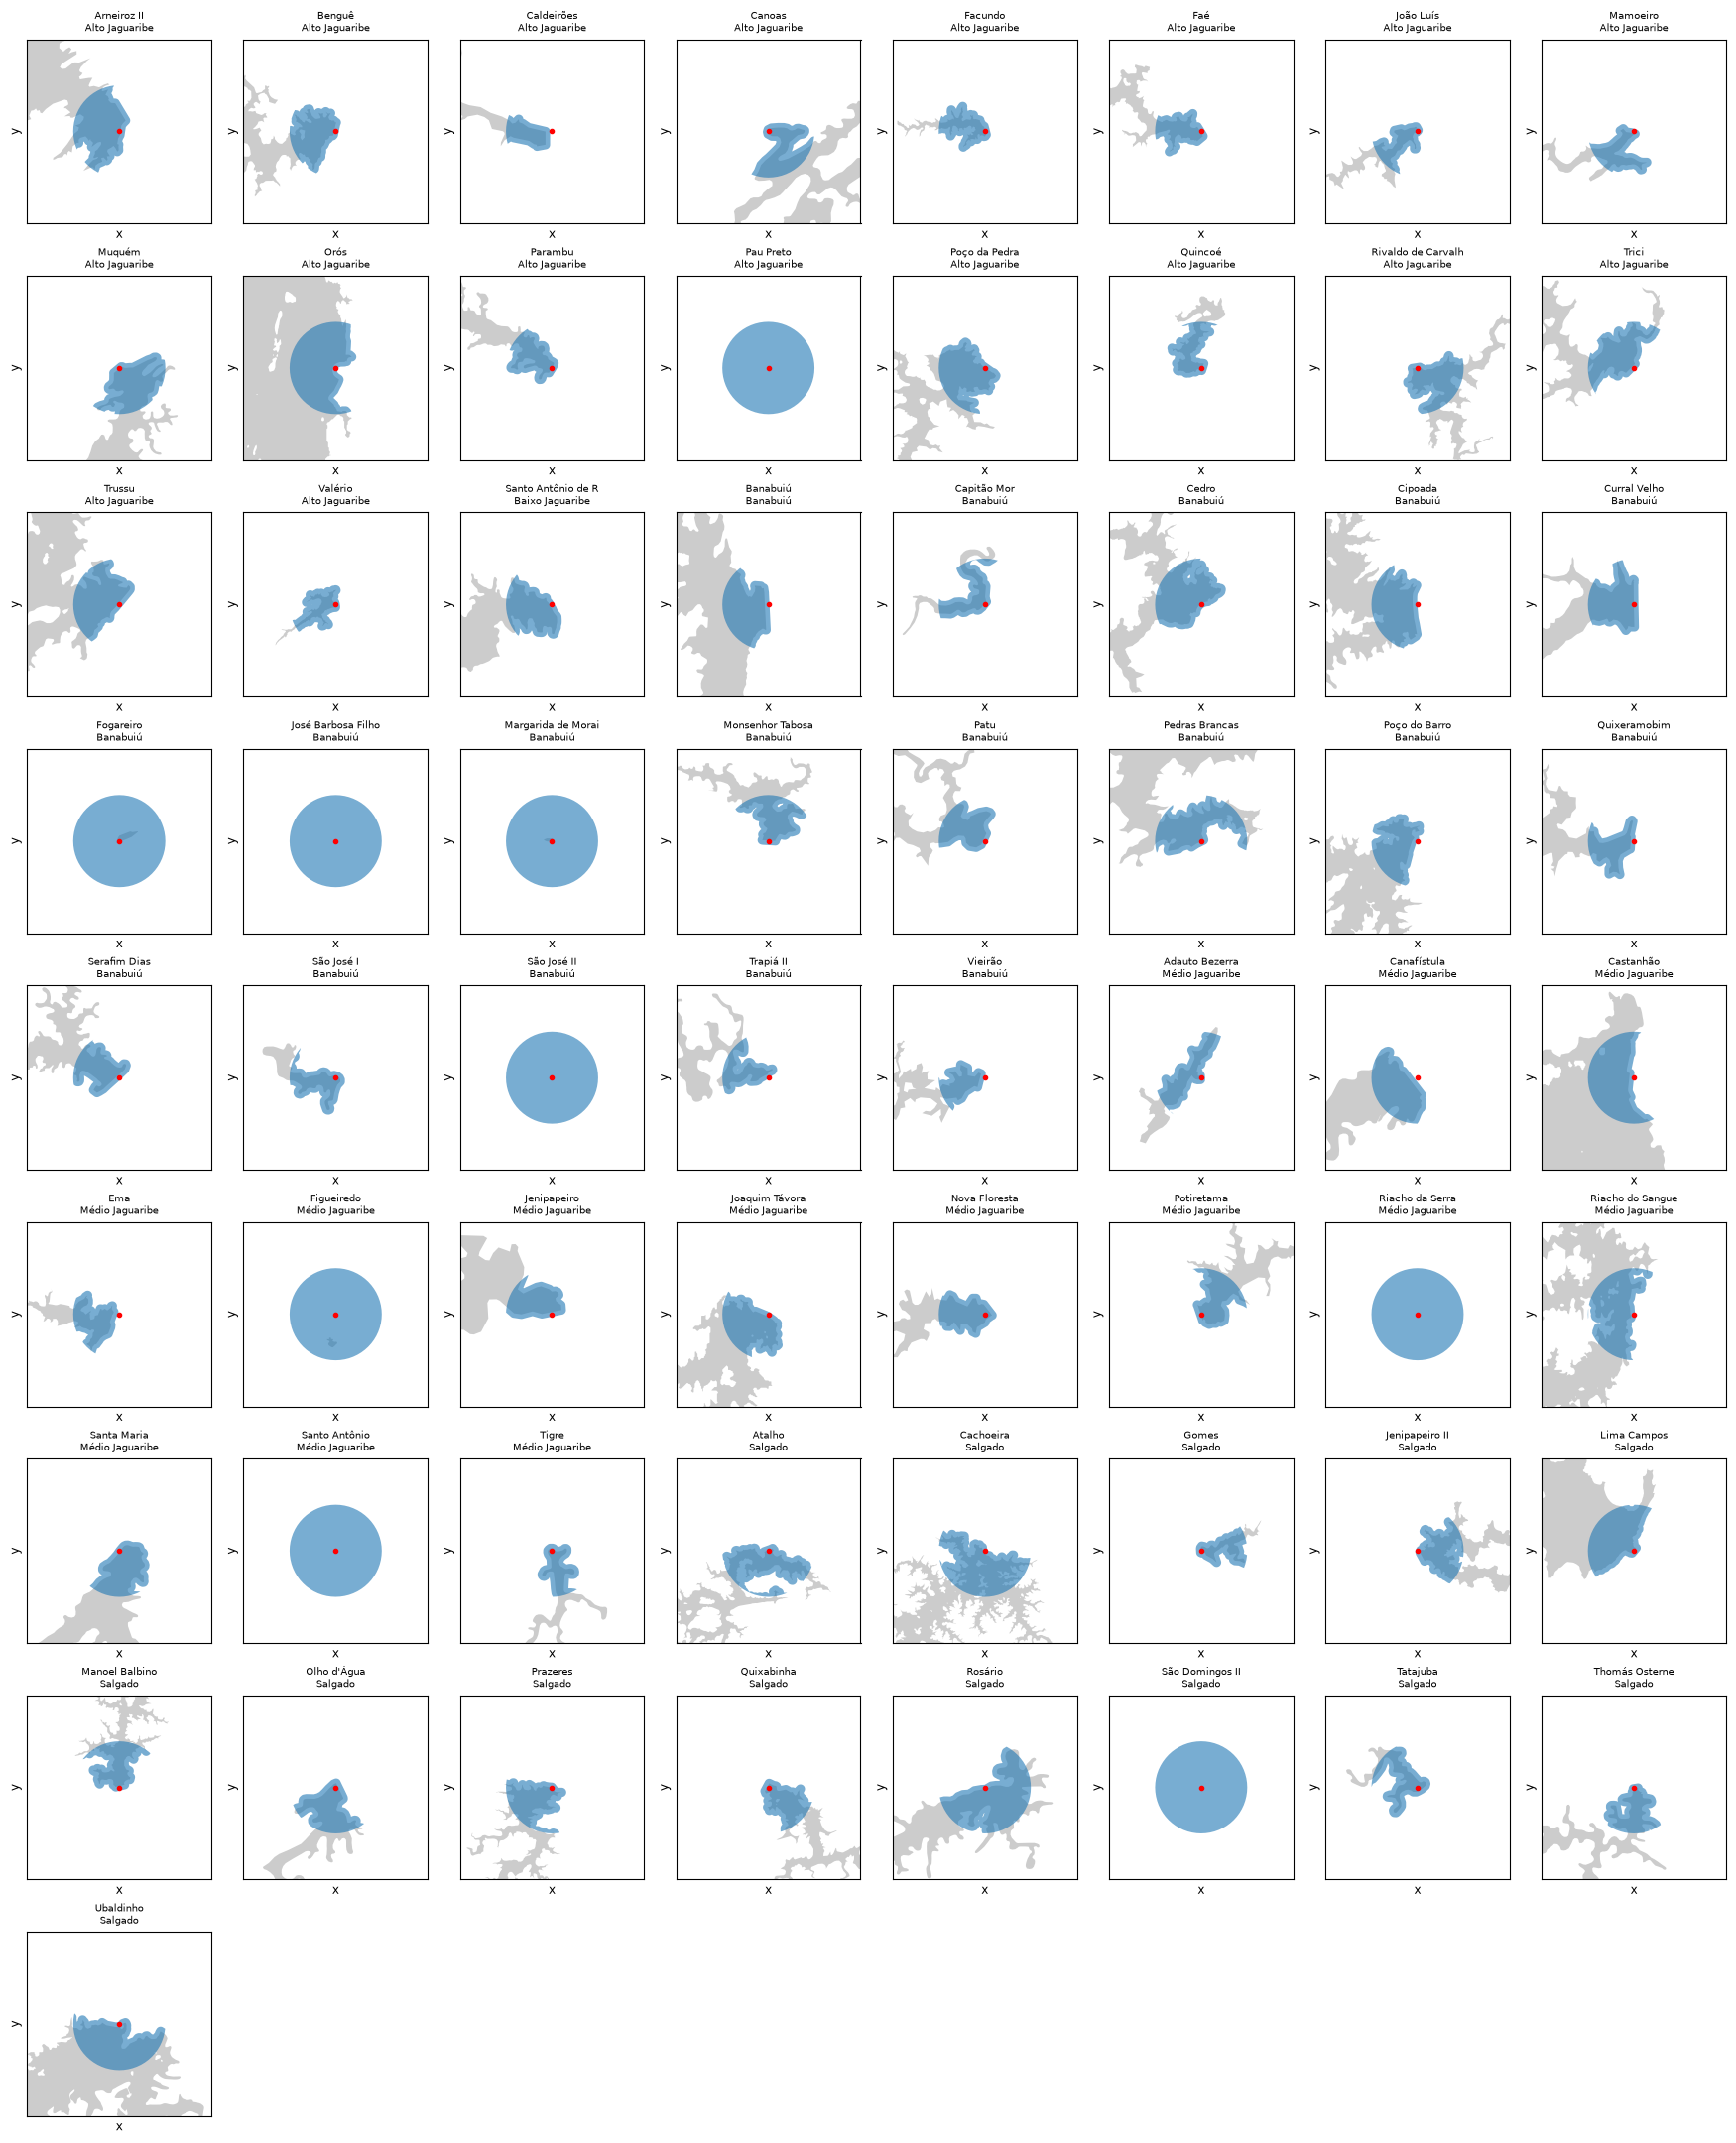

In [7]:
osm_poly = matched.set_index("reservoir").geometry.to_crs("EPSG:31984")
aoi = res.set_index("reservoir").to_crs("EPSG:31984")
jag = res[res["basin"].isin(JAGUARIBE)].sort_values(["basin", "name"])
n = len(jag); ncol = 8; nrow = -(-n // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 2.2, nrow * 2.4))
for ax, (_, r) in zip(axes.flat, jag.iterrows()):
    p = gpd.GeoSeries(gpd.points_from_xy([r.lon], [r.lat]), crs="EPSG:4326").to_crs("EPSG:31984").iloc[0]
    if r["match"] != "fallback_circle":
        gpd.GeoSeries([osm_poly[r.reservoir]]).plot(ax=ax, color="0.8")
    gpd.GeoSeries([aoi.loc[r.reservoir].geometry]).plot(ax=ax, color="tab:blue", alpha=0.6)
    ax.plot(p.x, p.y, "r.", ms=6)
    ax.set_xlim(p.x - 2000, p.x + 2000); ax.set_ylim(p.y - 2000, p.y + 2000)
    ax.set_title(f"{r['name'][:18]}\n{r['basin']}", fontsize=7); ax.set_xticks([]); ax.set_yticks([])
for ax in list(axes.flat)[n:]:
    ax.axis("off")
plt.tight_layout()
OUTPUTS.mkdir(exist_ok=True)
plt.savefig(OUTPUTS / "aoi_jaguaribe.png", dpi=110)
plt.show()

## Save

In [8]:
keep = ["reservoir", "name", "hidro_id", "basin", "lat", "lon", "match", "dist_m", "osm_type", "osm_id",
        "osm_name", "name_check", "osm_area_km2", "osm_trusted", "aoi_type", "aoi_km2", "n_campaigns"]
out = res[keep + ["geometry"]].copy()
out["jaguaribe_system"] = out["basin"].isin(JAGUARIBE)
out.to_file(PROCESSED / "reservoirs.geojson", driver="GeoJSON")
matched[["reservoir", "name", "basin", "osm_type", "osm_id", "osm_name", "match", "geometry"]].to_file(
    PROCESSED / "reservoirs_osm_polygons.geojson", driver="GeoJSON")

with_aoi = samples[samples["reservoir"].isin(out["reservoir"])]
print(len(out), "reservoirs written;", int(out["jaguaribe_system"].sum()), "in the Jaguaribe system")
print(len(with_aoi), "lab samples have an AOI;",
      int(with_aoi["reservoir"].isin(out.loc[out["jaguaribe_system"], "reservoir"]).sum()), "of them in the Jaguaribe system")

143 reservoirs written; 65 in the Jaguaribe system
3433 lab samples have an AOI; 1508 of them in the Jaguaribe system
